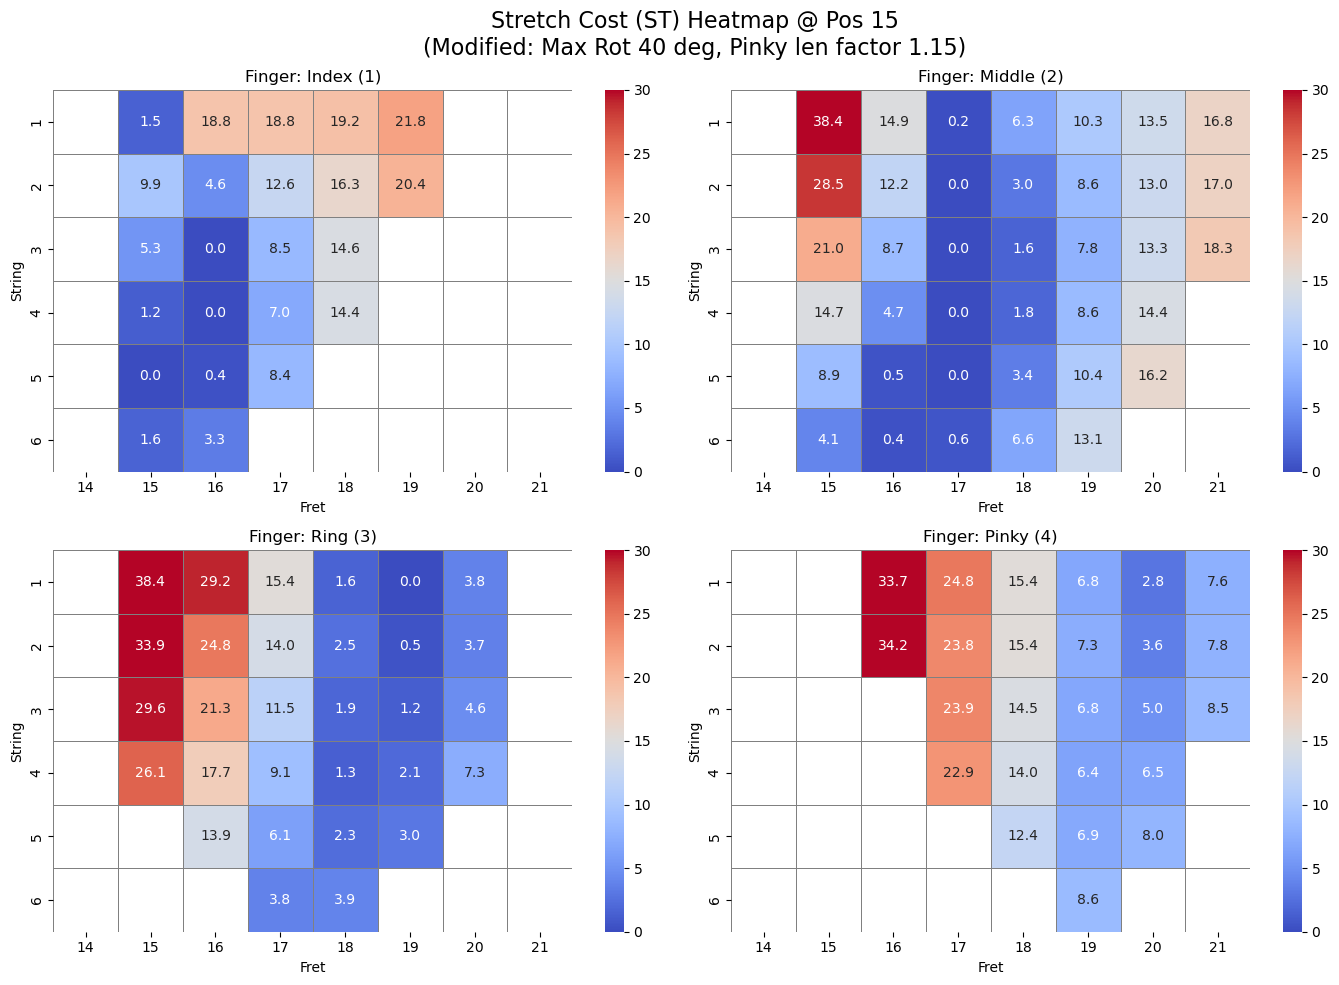

In [ ]:
import math
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np

# -----------------------------------------------------------------------------
# 1. Modified StretchModelAnalyzer Class
# -----------------------------------------------------------------------------
class StretchModelAnalyzer:
    def __init__(self, params=None):
        if params:
            self.p = params
            self.scaleLength = params.get('scaleLength', 635.0)
            self.stringSpacing = params.get('stringSpacing', 10.8)
            self.f_max = int(params.get('f_max', 24))
            self.s_max = int(params.get('s_max', 6))
            self.fingerLengths_mm = [0.0] + params.get('fingerLengths_mm', [70.0, 75.0, 70.0, 50.0])
            self.fingerDifficulty = params.get('fingerDifficulty', [1.0, 1.5, 2.0, 3.0]) 
            self.knuckleDist = [0.0, 0.0] + params.get('natural_min_spread_mm', [20.0, 40.0, 60.0])
        else:
            self.scaleLength = 635.0
            self.stringSpacing = 10.8
            self.f_max = 24
            self.s_max = 6
            self.fingerLengths_mm = [0.0, 70.0, 75.0, 70.0, 50.0]
            self.fingerDifficulty = [1.0, 1.5, 2.0, 3.0]
            self.knuckleDist = [0.0, 0.0, 20.0, 40.0, 60.0]

        self.limitRatios = [0.0, 1.0, 1.05, 1.05, 1.2]
        self.baseFactors = [0.0, 0.9, 1.0, 0.8, 1.0] # Maintained Pinky modification
        self.stringTension = {1: 1.0, 2: 1.0, 3: 1.0, 4: 1.2, 5: 1.4, 6: 1.6}
        self.breakAngleDeg = 15.0
        
        self.deg_to_rad = math.pi / 180.0
        self.rad_to_deg = 180.0 / math.pi
        self.tanTheta = math.tan(self.breakAngleDeg * self.deg_to_rad)
        
        self.fret_pos = [
            self.scaleLength - (self.scaleLength / (2 ** (f / 12.0)))
            for f in range(self.f_max + 1)
        ]

    def calculate_cost(self, hand_pos, finger_idx, string, fret):
        if fret < hand_pos: return 100000.0, 0.0

        pivotX = self.fret_pos[hand_pos]
        pivotY = 0.0 

        targetString = string
        maxRotation = 40.0 # Maintained from previous request
        
        # --- Modified Rotation Logic ---
        # Base rotation based on string (Str 6 -> 0, Str 1 -> -40)
        baseTheta = maxRotation * (targetString - 6.0) / 5.0
        
        # Additional rotation based on fret (Fret 17 -> 15 deg)
        # Assuming rotation increases in the same direction (negative)
        fretRotation = (fret / 17.0) * 15.0
        
        thetaDeg = baseTheta - fretRotation
        thetaRad = thetaDeg * self.deg_to_rad

        d = self.knuckleDist[finger_idx]
        kX = pivotX + (d * math.cos(thetaRad))
        kY = pivotY + (d * math.sin(thetaRad))

        tX = self.fret_pos[fret]
        tY = (string - 1) * self.stringSpacing 

        vX = tX - kX; vY = tY - kY
        dist = math.sqrt(vX*vX + vY*vY)
        
        neckFactor = 1.0
        if fret >= 15:
            ratioHigh = (fret - 15.0) / (self.f_max - 15.0)
            if ratioHigh > 1.0: ratioHigh = 1.0
            neckFactor = 1.0 - (0.15 * ratioHigh)
        
        eff_len = self.fingerLengths_mm[finger_idx] * self.baseFactors[finger_idx] * neckFactor
        limit = self.limitRatios[finger_idx]

        distCost = 0.0
        if eff_len > 0 and dist > eff_len * limit:
            return 100000.0, 0.0 

        if eff_len > 0:
            ratio = dist / eff_len
            if ratio < 0.3:
                distCost += (0.3 - ratio) * 5.0
            elif ratio <= 0.7:
                distCost += 0.0
            else:
                distCost += (ratio - 0.7) * 10.0
                if ratio > 1.0:
                    distCost += (ratio - 1.0) * 20.0

        angleCost = 0.0
        dotProd = vX * -math.sin(thetaRad) + vY * math.cos(thetaRad)
        cosDelta = dotProd / dist if dist > 0.001 else 1.0
        cosDelta = max(-1.0, min(1.0, cosDelta))
        deltaDeg = math.acos(cosDelta) * self.rad_to_deg

        baseMaxAngle = 20.0 if finger_idx == 4 else 15.0
        maxAngle = baseMaxAngle
        if fret >= 12:
            maxAngle = max(10.0, baseMaxAngle - (fret - 12) * 0.5)

        if deltaDeg > maxAngle:
            angleCost += (deltaDeg - maxAngle) * 0.5
        
        diff_val = self.fingerDifficulty[finger_idx - 1]

        st_cost = distCost + angleCost

        a = 0.5 + (2.0 * fret / 12.0) 
        l_vib = self.scaleLength - self.fret_pos[fret] 
        tau = self.stringTension.get(string, 1.0) 
        forceF = (2.0 * tau * a) / (l_vib * self.tanTheta)
        
        dh_cost = (forceF * 200.0) * diff_val
        
        return st_cost, dh_cost

# -----------------------------------------------------------------------------
# 2. Visualization Function
# -----------------------------------------------------------------------------
def plot_st_cost_heatmap(analyzer, target_hand_pos=5, weight=1.0):
    fingers = {1: "Index (1)", 2: "Middle (2)", 3: "Ring (3)", 4: "Pinky (4)"}
    fig, axes = plt.subplots(2, 2, figsize=(14, 10))
    axes = axes.flatten()
    
    min_fret = max(0, target_hand_pos - 1)
    max_fret = target_hand_pos + 6
    fret_range = range(min_fret, max_fret + 1)
    string_range = range(1, 7)

    for i, (f_idx, f_name) in enumerate(fingers.items()):
        data = []
        for s in string_range:
            row = []
            for f in fret_range:
                st_c, dh_c = analyzer.calculate_cost(target_hand_pos, f_idx, s, f)
                if st_c > 50000: 
                    val = None 
                else:
                    val = st_c * weight
                row.append(val)
            data.append(row)
        
        df = pd.DataFrame(data, index=list(string_range), columns=list(fret_range)).astype(float)
        
        sns.heatmap(df, ax=axes[i], cmap="coolwarm", annot=True, fmt=".1f", 
                    cbar=True, vmin=0, vmax=30, mask=df.isnull(),
                    linewidths=.5, linecolor='gray')
        
        axes[i].set_title(f"Finger: {f_name}")
        axes[i].set_ylabel("String")
        axes[i].set_xlabel("Fret")

    plt.suptitle(f"Stretch Cost (ST) Heatmap @ Pos {target_hand_pos}\n(Modified: High Fret Rotation added)", fontsize=16)
    plt.tight_layout()
    plt.show()

# -----------------------------------------------------------------------------
# 3. Execution
# -----------------------------------------------------------------------------
params = {
    'scaleLength': 635.0,
    'stringSpacing': 10.8,
    'f_max': 22,
    's_max': 6,
    'fingerLengths_mm': [70.0, 75.0, 70.0, 50.0],
    'fingerDifficulty': [1.0, 1.5, 2.0, 3.0],
    'natural_min_spread_mm': [20.0, 40.0, 60.0]
}

analyzer = StretchModelAnalyzer(params)
# Visualize at a higher position (e.g., 12) to see the effect more clearly?
# The user mentioned "17th fret", let's show heatmap at pos 12 to include high frets.
plot_st_cost_heatmap(analyzer, target_hand_pos=12, weight=1.0)

--- Physics Cost Calculation (v18) ---
Fret  | 1st Str  | 6th Str 
------------------------------
0     | 1.18     | 1.88
12    | 11.75     | 18.81
24    | 42.32    | 67.71
------------------------------
0     | 1.18     | 1.88
12    | 11.75     | 18.81
24    | 42.32    | 67.71
------------------------------


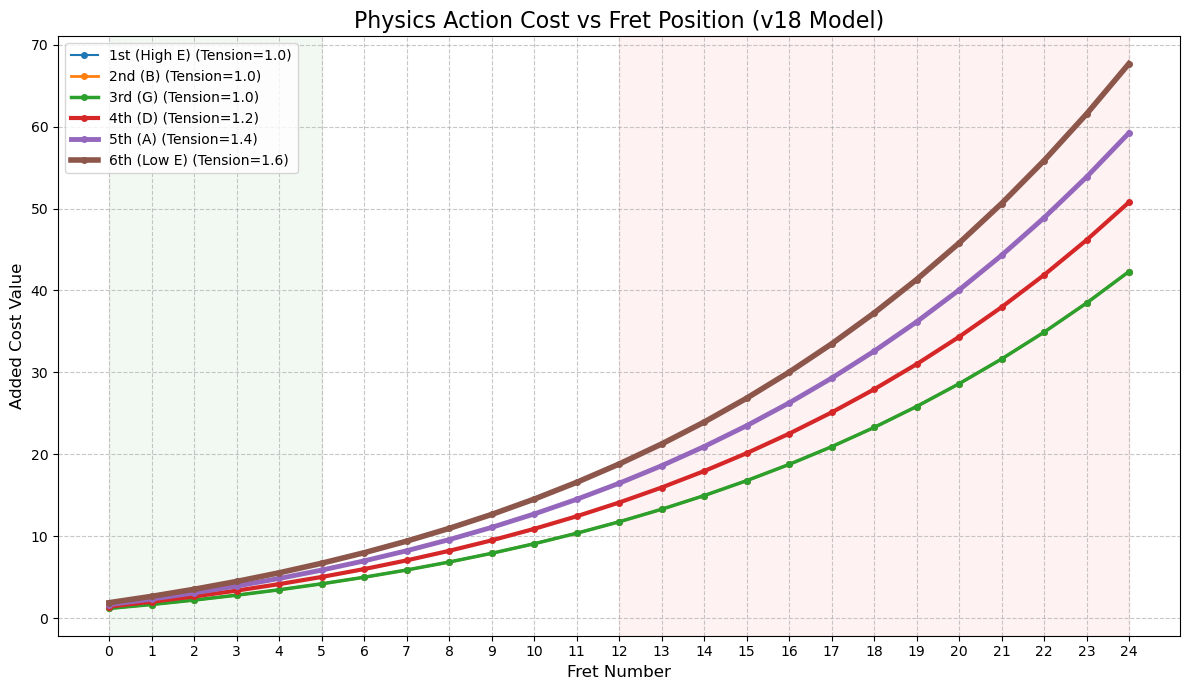

In [77]:
import matplotlib.pyplot as plt
import numpy as np
import math

# =============================================================================
# 1. 物理モデル計算ロジック (v18: Additive Hybrid Model - Physics Component)
# =============================================================================
class PhysicsCostAnalyzer:
    def __init__(self):
        # ギターパラメータ
        self.scaleLength = 635.0
        self.f_max = 24
        self.s_max = 6
        
        # 物理パラメータ (Grimes Model)
        # 弦ごとの張力係数 (1弦=1.0, 6弦=1.6)
        self.stringTension = {1: 1.0, 2: 1.0, 3: 1.0, 4: 1.2, 5: 1.4, 6: 1.6}
        
        # ブリッジ折れ角 (15度)
        self.breakAngleDeg = 15.0
        self.deg_to_rad = math.pi / 180.0
        self.tanTheta = math.tan(self.breakAngleDeg * self.deg_to_rad)
        
        # フレット位置 (ナットからの距離)
        self.fret_pos = [
            self.scaleLength - (self.scaleLength / (2 ** (f / 12.0)))
            for f in range(self.f_max + 1)
        ]

    def calculate_physics_cost(self, string, fret):
        """
        Grimes (2014) の物理モデルに基づく「物理アクションコスト」のみを計算
        Cost = (2 * tau * a) / (l * tan(theta)) * ScalingFactor
        """
        # Action (a): 弦高
        # 0フレットで0.5mm, 12フレットで2.5mm と仮定した線形増加モデル
        # 高フレットほど弦が高くなり、押さえる距離が増える
        action_mm = 0.5 + (2.0 * fret / 12.0)
        
        # Vibrating Length (l): 振動弦長
        # フレットからブリッジまでの距離 (スケール - ナットからの距離)
        # 高フレットほど弦が短くなり、張りが強くなる(突っ張る)
        l_vib = self.scaleLength - self.fret_pos[fret]
        
        # Tension (tau): 張力係数
        tau = self.stringTension.get(string, 1.0)
        
        # Force Index (F): 押弦に必要な力に比例する指数
        if l_vib <= 0: return 0.0 # Error handling
        
        forceF = (2.0 * tau * action_mm) / (l_vib * self.tanTheta)
        
        # コストへの変換係数 (v18設定: 200.0)
        # これにより、数ポイント〜数十ポイントの加算コストになる
        physicsCost = forceF * 200.0
        
        return physicsCost

# =============================================================================
# 2. 可視化実行
# =============================================================================
def plot_physics_cost_distribution():
    analyzer = PhysicsCostAnalyzer()
    
    # フレット範囲 (0〜24)
    frets = np.arange(0, 25, 1)
    
    # プロット設定
    plt.figure(figsize=(12, 7))
    
    # 各弦についてプロット (1弦〜6弦)
    colors = ['#FFD700', '#FFA500', '#FF4500', '#800080', '#0000FF', '#000080']
    labels = ['1st (High E)', '2nd (B)', '3rd (G)', '4th (D)', '5th (A)', '6th (Low E)']
    
    print("--- Physics Cost Calculation (v18) ---")
    print(f"{'Fret':<5} | {'1st Str':<8} | {'6th Str':<8}")
    print("-" * 30)

    for s in range(1, 7):
        costs = []
        for f in frets:
            c = analyzer.calculate_physics_cost(s, f)
            costs.append(c)
            
        # グラフ描画
        # 弦番号が大きい(低音弦)ほど太く表示
        lw = 1.0 + (s * 0.5)
        plt.plot(frets, costs, marker='o', markersize=4, linewidth=lw, 
                 label=f'{labels[s-1]} (Tension={analyzer.stringTension[s]})')
        
        # データ確認用出力 (0, 12, 24フレットのみ)
        if s in [1, 6]:
            print(f"{0:<5} | {analyzer.calculate_physics_cost(1,0):.2f}     | {analyzer.calculate_physics_cost(6,0):.2f}")
            print(f"{12:<5} | {analyzer.calculate_physics_cost(1,12):.2f}     | {analyzer.calculate_physics_cost(6,12):.2f}")
            print(f"{24:<5} | {analyzer.calculate_physics_cost(1,24):.2f}    | {analyzer.calculate_physics_cost(6,24):.2f}")
            print("-" * 30)

    plt.title("Physics Action Cost vs Fret Position (v18 Model)", fontsize=16)
    plt.xlabel("Fret Number", fontsize=12)
    plt.ylabel("Added Cost Value", fontsize=12)
    
    plt.grid(True, which='both', linestyle='--', alpha=0.7)
    plt.legend(fontsize=10)
    plt.xticks(np.arange(0, 25, 1))
    
    # ゾーンの注釈
    plt.axvspan(0, 5, color='green', alpha=0.05, label='Low Pos')
    plt.axvspan(12, 24, color='red', alpha=0.05, label='High Pos')
    
    plt.tight_layout()
    plt.show()

if __name__ == "__main__":
    plot_physics_cost_distribution()